In [1]:
# Import Required Libraries

In [2]:
# TensorFlow for deep learning
import tensorflow as tf

# Numerical computations
import numpy as np

# Data handling
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and folder handling
import os

# Image preprocessing utilities
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Pretrained ResNet50 model
from tensorflow.keras.applications import ResNet50

# Neural network layers and model creation
from tensorflow.keras import layers, models

# Evaluation metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix


In [3]:
# Verify TensorFlow Version

In [4]:
# Print TensorFlow version
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.18.0


In [5]:
# Define Dataset Path

In [6]:
# Path to dataset directory
dataset_path = "../dataset"

# Display available class folders
print(os.listdir(dataset_path))

['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']


In [7]:
# Count Images Per Class

In [8]:
# Loop through dataset folders
for folder in os.listdir(dataset_path):

    # Full path
    path = os.path.join(dataset_path, folder)

    # Check if directory exists
    if os.path.isdir(path):

        # Print class name and image count
        print(folder, len(os.listdir(path)))

Dyskeratotic 1851
Koilocytotic 1889
Metaplastic 1858
Parabasal 1683
Superficial-Intermediate 1789


In [9]:
# Load and Preprocess Images

In [10]:
# Define image dimensions
IMG_SIZE = 224

# Define batch size
BATCH_SIZE = 32

# Create image generator
datagen = ImageDataGenerator(

    # Normalize pixel values
    rescale=1./255,

    # Validation split
    validation_split=0.2
)

# Load training images
train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

# Load validation images
val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Found 4014 images belonging to 5 classes.
Found 1001 images belonging to 5 classes.


In [11]:
# Display Class Labels

In [12]:
# Print class labels
print(train_data.class_indices)

{'Dyskeratotic': 0, 'Koilocytotic': 1, 'Metaplastic': 2, 'Parabasal': 3, 'Superficial-Intermediate': 4}


In [13]:
# Visualize Sample Images

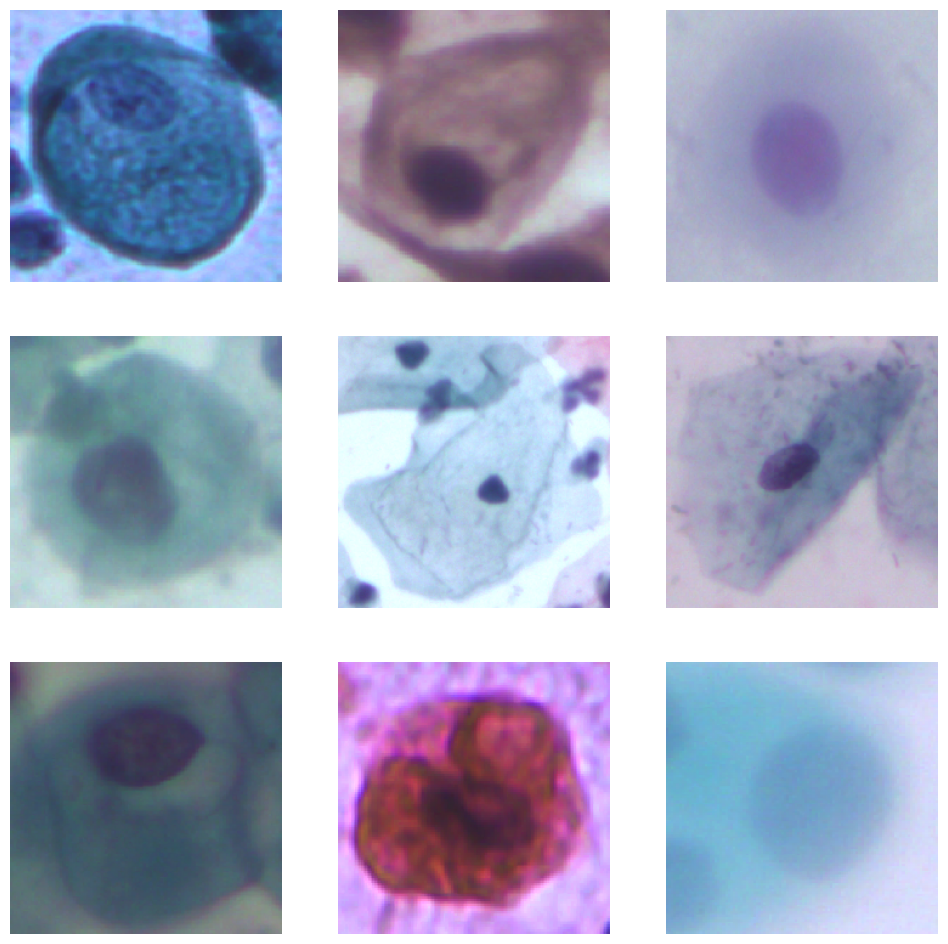

In [14]:
# Retrieve one batch of images
images, labels = next(train_data)

# Create display figure
plt.figure(figsize=(12,12))

# Display first 9 images
for i in range(9):

    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.axis('off')

# Show images
plt.show()

In [15]:
# Build ResNet50 Model

In [17]:
# Load pretrained ResNet50 model
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [18]:
# Freeze pretrained layers
base_model.trainable = False

# Build classification model
model = models.Sequential([

    # ResNet50 feature extractor
    base_model,

    # Convert feature maps to vectors
    layers.GlobalAveragePooling2D(),

    # Dense layer
    layers.Dense(128, activation='relu'),

    # Reduce overfitting
    layers.Dropout(0.5),

    # Output layer for 5 classes
    layers.Dense(5, activation='softmax')
])

In [19]:
# Compile Model

In [20]:
# Configure model training
model.compile(

    # Optimization algorithm
    optimizer='adam',

    # Multi-class classification loss
    loss='categorical_crossentropy',

    # Accuracy metric
    metrics=['accuracy']
)

In [21]:
 # View Model Summary

In [22]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape              ┃        Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)              │ (None, 7, 7, 2048)        │     23,587,712 │
├────────────────────────────────────┼───────────────────────────┼────────────────┤
│ global_average_pooling2d           │ (None, 2048)              │              0 │
│ (GlobalAveragePooling2D)           │                           │                │
├────────────────────────────────────┼───────────────────────────┼────────────────┤
│ dense (Dense)                      │ (None, 128)               │        262,272 │
├────────────────────────────────────┼───────────────────────────┼────────────────┤
│ dropout (Dropout)                  │ (None, 128)               │              0 │
├────────────────────────────────────┼───────────────────────────┼────────────────┤
│ dense_1 (Dense)                    │ (None, 5)                 │            645 │
└────────────────────────────────────┴───────────────────────────┴────────────────┘

 Total params: 23,850,629 (90.98 MB)

 Trainable params: 262,917 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [23]:
# Train Model

In [24]:
# Train the ResNet50 model
history = model.fit(

    # Training dataset
    train_data,

    # Validation dataset
    validation_data=val_data,

    # Number of epochs
    epochs=10
)

Epoch 1/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step - accuracy: 0.2050 - loss: 1.6351 - val_accuracy: 0.2118 - val_loss: 1.6088
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.2018 - loss: 1.6083 - val_accuracy: 0.2118 - val_loss: 1.6081
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 224s 2s/step - accuracy: 0.2045 - loss: 1.6079 - val_accuracy: 0.1608 - val_loss: 1.6066
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 217s 2s/step - accuracy: 0.2133 - loss: 1.6080 - val_accuracy: 0.2118 - val_loss: 1.6075
Epoch 5/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 232s 2s/step - accuracy: 0.2020 - loss: 1.6075 - val_accuracy: 0.2118 - val_loss: 1.6074
Epoch 6/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.2115 - loss: 1.6074 - val_accuracy: 0.2118 - val_loss: 1.6074
Epoch 7/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 223s 2s/step - accuracy: 0.2060 - loss: 1.6074 - val_accuracy: 0.2138 - val_loss: 1.6073
Epoch 8/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.2048 - loss: 1.6073 - val_accu

In [ ]:
# Plot Accuracy Graph

In [ ]:
# Plot training accuracy
plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

# Plot validation accuracy
plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

# Labels
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

# Show legend
plt.legend()

# Display graph
plt.show()

In [ ]:
# Plot Loss Graph

In [ ]:
# Plot training loss
plt.plot(
    history.history['loss'],
    label='Training Loss'
)

# Plot validation loss
plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

# Labels
plt.xlabel('Epoch')
plt.ylabel('Loss')

# Show legend
plt.legend()

# Display graph
plt.show()

In [ ]:
# Evaluate Model

In [ ]:
# Evaluate model performance
loss, accuracy = model.evaluate(val_data)

# Print validation accuracy
print("Validation Accuracy:", accuracy)

In [ ]:
# Generate Predictions

In [ ]:
# Generate predictions
predictions = model.predict(val_data)

# Convert probabilities into class labels
predicted_classes = np.argmax(predictions, axis=1)

# Actual class labels
true_classes = val_data.classes

# Retrieve class names
class_labels = list(val_data.class_indices.keys())

In [ ]:
# Classification Report

In [ ]:
# Print precision, recall and F1-score
print(classification_report(
    true_classes,
    predicted_classes,
    target_names=class_labels
))

In [ ]:
# Confusion Matrix

In [ ]:
# Generate confusion matrix
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

# Create visualization figure
plt.figure(figsize=(8,6))

# Display heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

# Labels
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Title
plt.title('Confusion Matrix')

# Display heatmap
plt.show()

In [ ]:
# Save Model

In [ ]:
# Save trained ResNet50 model
model.save("../models/resnet50_papsmear.h5")